# Una esfera en la trampa calculada: espectro, rigidez y ley de Boltzmann

**Pregunta:** ¿Qué hace una esfera atrapada en el potencial que calculó DinHot, y el espectro de potencia de su movimiento devuelve la rigidez de la trampa?

- Nivel: 1, fundamentos.
- Requisitos previos: `03-gerchberg-saxton/02-weights-for-uniformity` para el holograma, y `01-fourier-optics/02-reading-a-trap-array` para las intensidades de las trampas.
- Tiempo de lectura: unos 25 minutos. El notebook se ejecuta en cerca de un minuto.

## Objetivos

Un holograma se juzga con los números de los temas anteriores, trampas iguales y una eficiencia alta, pero su propósito es sostener algo. Este notebook cierra el lazo: toma la intensidad que produce un holograma, la convierte en el potencial que siente una esfera, deja que la esfera difunda en él y pregunta si un experimentador que mirara la esfera podría recuperar la rigidez de la trampa a partir de su movimiento. Así se calibran las pinzas ópticas, y es la verificación de que la física del producto es coherente consigo misma. Al terminar puedes:

- convertir un mapa de intensidad focal en una profundidad y una rigidez de trampa, conservando las unidades;
- decir qué hace una esfera sobreamortiguada, y qué paso del integrador es estable;
- calcular el espectro de potencia de la posición, ajustar una lorentziana y leer la frecuencia de corte;
- contrastar el histograma de posiciones simulado con la ley de Boltzmann;
- decir qué prueba la verificación, y qué deja abierto.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.dynamics import BeadParams, bead_trajectory, boltzmann_check, fit_lorentzian, psd
from pipeline.model.holo.core.forward import point_trap_fields
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet
from pipeline.model.holo.core.trapphys import C_M_PER_S, EPS0_F_PER_M, KB_J_PER_K, rayleigh_polarizability_Fm2
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C01 de `data/examples/cases.json`: un arreglo de 3 x 3 con una esfera de tipo poliestireno en su trampa central.

- Propietario: este repositorio; el caso es sintético, con la esfera y el fluido declarados en el registro y el arreglo en el montaje óptico de tipo atómico del caso.
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C01 (el bloque `dynamics` lleva la esfera).

In [2]:
# caso C01: un arreglo de 3 x 3, y el registro de la esfera que está en su trampa central
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C01"]
setup = build.setup_of(rec)
target = build.target_of(rec)
bead = rec["dynamics"]
print(rec["case_id"], "|", len(target.traps), "trampas | trampa de la esfera:", bead["trap_id"])
keys = ("bead_radius_um", "n_particle", "power_mw", "viscosity_pa_s", "temperature_k", "n_steps", "dt_s")
print({k: bead[k] for k in keys})

C01_square_grid | 9 trampas | trampa de la esfera: 4
{'bead_radius_um': 0.5, 'n_particle': 1.59, 'power_mw': 10.0, 'viscosity_pa_s': 0.00089, 'temperature_k': 295.0, 'n_steps': 131072, 'dt_s': 5e-05}


## Método

### Paso 1: un holograma, y la intensidad que deja alrededor de una trampa

Una esfera dieléctrica pequeña en un haz enfocado siente la fuerza de gradiente $F = \tfrac{1}{2}\,\mathrm{Re}(\alpha)\,\nabla I / (c\,\epsilon_0)$, donde $\alpha$ es su polarizabilidad e $I$ la intensidad. En el régimen de Rayleigh $\alpha = 4\pi r^3 \epsilon_0 (\epsilon_r - 1)/(\epsilon_r + 2)$ con $\epsilon_r = (n_\text{partícula}/n_\text{medio})^2$ (Grimm, Weidemuller y Ovchinnikov, 2000, para la fuerza dipolar; la ficha de física del pipeline para la esfera). La fuerza es el gradiente de un potencial $U(\mathbf r) = -U_0\, I(\mathbf r)/I_\text{máx}$ con $U_0 = \alpha I_\text{máx} / (2 c \epsilon_0)$, de modo que la esfera está en el mismo mapa de intensidad que calcula el holograma. La primera celda calcula el holograma del arreglo de 3 x 3 con Gerchberg-Saxton ponderado (M06).

In [3]:
# el holograma del arreglo: GS ponderado sobre el modelo ideal, 30 iteraciones
res = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
h = res.history[-1]
print(f"eficiencia {h['efficiency']:.4f} | uniformidad {h['uniformity']:.4f} | "
      f"desv. rel. {h['rel_std']:.2f} %")

eficiencia 0.8166 | uniformidad 1.0000 | desv. rel. 0.00 %


El arreglo es perfectamente igual (uniformidad 1,0000) con 0,8166 de la luz en las nueve trampas. El potencial necesita más que los nueve números $I_m$: necesita la forma de un punto, así que la celda siguiente evalúa la intensidad del holograma en una malla fina, 51 x 51 puntos separados una décima de bin de FFT, alrededor de la trampa central. La forma de trampas puntuales evalúa el campo en cualquier posición, no solo en los bins de la FFT.

In [4]:
# la intensidad alrededor de la trampa central: 51 x 51 puntos, separados 0.1 bin de FFT, desde la forma de
# trampas puntuales
bin_m = focal_bin_m(setup)
site = next(t for t in rec["target"]["traps"] if t["id"] == bead["trap_id"])
side = 51
offset = (np.arange(side) - side // 2) * 0.1 * bin_m
xs, ys = site["x_um"] * 1e-6 + offset, site["y_um"] * 1e-6 + offset
grid = TrapSet(Trap(iy * side + ix, float(xs[ix]), float(ys[iy]), 0.0) for iy in range(side) for ix in range(side))
inten = (np.abs(point_trap_fields(res.phi, setup, grid)) ** 2).reshape(side, side)
iy_max, ix_max = np.unravel_index(int(np.argmax(inten)), inten.shape)
print(f"pico del mapa: {inten.max():.4f} de la potencia de entrada")
print(f"posición del pico respecto del centro de la trampa (um): "
      f"{(xs[ix_max] - site['x_um'] * 1e-6) * 1e6:.3f}, {(ys[iy_max] - site['y_um'] * 1e-6) * 1e6:.3f}")

pico del mapa: 0.0907 de la potencia de entrada
posición del pico respecto del centro de la trampa (um): 0.000, 0.000


El pico del mapa es 0,0907 de la potencia de entrada, en el centro de la trampa, como debe ser. Para convertirlo en newtons la celda escala por la potencia del láser en el SLM, 10 mW, dividida por el área de un bin en el plano focal (un bin lleva $1/\text{pad}^2$ de la potencia de un pico), toma la profundidad $U_0$ de la polarizabilidad, y la curvatura de $I/I_\text{máx}$ en el pico con una segunda diferencia de dos pasos de malla. La rigidez a lo largo de $x$ es $\kappa = U_0 \times$ curvatura. El arrastre es el de Stokes, $\gamma = 6\pi\eta r$, y la esfera sobreamortiguada tiene entonces un tiempo de relajación $\tau = \gamma/\kappa$ y una frecuencia de corte $f_c = \kappa / (2\pi\gamma)$ (Tolic-Norrelykke et al., 2006).

In [5]:
# del mapa a la física: profundidad de la trampa, rigidez a lo largo de x, arrastre y frecuencia de corte
# esperada
power = bead["power_mw"] * 1e-3
peak_intensity = inten.max() * power / (setup.pad**2 * bin_m**2)
alpha = rayleigh_polarizability_Fm2(bead["bead_radius_um"] * 1e-6, bead["n_particle"], setup.n_imm)
depth = alpha * peak_intensity / (2.0 * C_M_PER_S * EPS0_F_PER_M)
step = 0.1 * bin_m
peak_row = inten[iy_max]
curvature = -(peak_row[ix_max + 2] - 2 * peak_row[ix_max] + peak_row[ix_max - 2]) / (2 * step) ** 2 / inten.max()
kappa = depth * curvature
gamma = 6.0 * np.pi * bead["viscosity_pa_s"] * bead["bead_radius_um"] * 1e-6
fc_expected = kappa / (2.0 * np.pi * gamma)
kt = KB_J_PER_K * bead["temperature_k"]
print(f"profundidad {depth / kt:.1f} kBT | rigidez {kappa * 1e6:.2f} pN/um | "
      f"arrastre {gamma:.3e} N s/m")
print(f"frecuencia de corte esperada {fc_expected:.2f} Hz | "
      f"tiempo de relajación {gamma / kappa * 1e3:.3f} ms")

profundidad 198.5 kBT | rigidez 4.08 pN/um | arrastre 8.388e-09 N s/m
frecuencia de corte esperada 77.33 Hz | tiempo de relajación 2.058 ms


La esfera está 198,5 veces más profunda en el potencial que la energía térmica, con una rigidez de 4,08 pN/um, un tiempo de relajación de 2,058 ms y una frecuencia de corte esperada de 77,33 Hz. La magnitud de la profundidad hereda una salvedad de la ficha de física del pipeline: la polarizabilidad conserva el prefactor del vacío y los factores adicionales del medio para una esfera en un fluido no están en las secciones que leyó el pipeline, de modo que la rigidez absoluta es un valor del modelo y no una medición. La verificación siguiente no depende de ello, porque el espectro se contrasta con la rigidez que usó la propia simulación.

### Paso 2: la corrida de Langevin

Una esfera sobreamortiguada obedece $x_{n+1} = x_n + (\Delta t/\gamma)\,F(x_n) + \sqrt{2 D \Delta t}\,\zeta_n$, con $D = k_B T/\gamma$ y $\zeta_n$ un número normal estándar del generador con semilla. El paso debe resolver la relajación, y la regla del pipeline es $\Delta t \le \tau/20$. El paso del registro, de 50 us, ya es menor que $\tau/20$ = 103 us, así que la celda integra con el paso del registro; conserva la forma general, que refina el paso y diezma la traza cuando una trampa más rígida lo necesita. Ejecuta 131072 pasos y compara la dispersión de la posición con el valor de equipartición $\sqrt{k_B T/\kappa}$.

In [6]:
# la corrida de Langevin: el paso del registro, refinado hasta ser a lo sumo tau / 20, y luego diezmado al
# paso del registro
tau = gamma / kappa
sub = max(1, int(np.ceil(bead["dt_s"] / (tau / 20))))
start = (xs[ix_max], ys[iy_max])
params = BeadParams(depth, gamma, bead["temperature_k"], start)
dt_fine = bead["dt_s"] / sub
track = bead_trajectory(inten, (xs, ys), params, bead["n_steps"] * sub, dt_fine, Rng(rec["seed"] + 7919))[::sub]
x = track[:, 0] - start[0]
print(f"pasos del integrador por paso del registro: {sub} | muestras: {len(x)}")
print(f"posición rms {x.std() * 1e9:.1f} nm | equipartición sqrt(kBT / kappa) "
      f"{np.sqrt(kt / kappa) * 1e9:.1f} nm")

pasos del integrador por paso del registro: 1 | muestras: 131073
posición rms 32.7 nm | equipartición sqrt(kBT / kappa) 31.6 nm


El panel izquierdo superpone las primeras 3000 posiciones de la esfera sobre el mapa de intensidad, y el derecho muestra 2000 muestras de la posición x frente al tiempo.

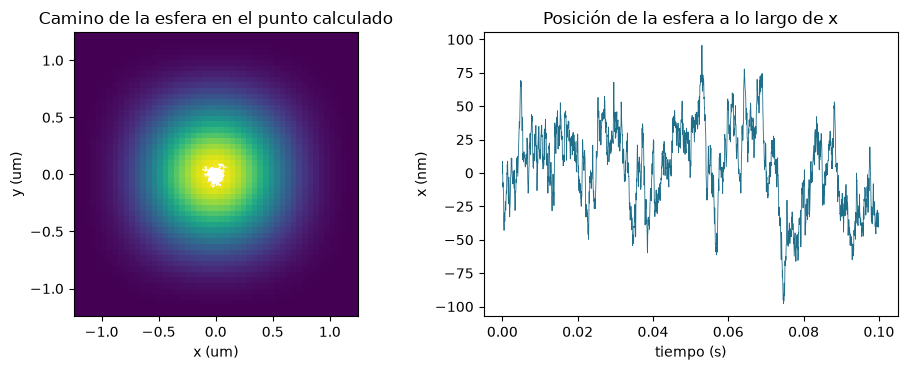

In [7]:
# izquierda: el mapa de intensidad con las primeras 3000 posiciones de la esfera; derecha: la posición x
# frente al tiempo
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.8))
extent = [(xs[0] - start[0]) * 1e6, (xs[-1] - start[0]) * 1e6, (ys[0] - start[1]) * 1e6, (ys[-1] - start[1]) * 1e6]
a.imshow(inten, origin="lower", extent=extent, cmap="viridis")
a.plot((track[:3000, 0] - start[0]) * 1e6, (track[:3000, 1] - start[1]) * 1e6, "w-", linewidth=0.4)
a.set_xlabel("x (um)")
a.set_ylabel("y (um)")
a.set_title("Camino de la esfera en el punto calculado")
t_axis = np.arange(2000) * bead["dt_s"]
b.plot(t_axis, x[:2000] * 1e9, color="#1f6f8b", linewidth=0.6)
b.set_xlabel("tiempo (s)")
b.set_ylabel("x (nm)")
b.set_title("Posición de la esfera a lo largo de x")
plt.tight_layout()
plt.show()

La posición rms es 32,7 nm frente al valor de equipartición de 31,6 nm, una diferencia de 3 por ciento que es el error estadístico de una corrida finita: la posición se correlaciona durante el tiempo de relajación de 2 ms, así que 131072 muestras de 50 us abarcan solo unos 3000 tiempos de relajación. En el panel izquierdo la esfera se mantiene a una décima de micrómetro del centro de un punto de cerca de un micrómetro de ancho, de modo que está bien dentro de la región donde el potencial es casi armónico; la traza blanca cubre una fracción diminuta del núcleo brillante. En el panel derecho la posición vaga en unos 100 nm con correlaciones que duran varios milisegundos. La figura muestra una esfera y una semilla; no muestra que el potencial sea armónico en todo el camino, lo que prueba la verificación de Boltzmann más abajo.

### Paso 3: el espectro y la rigidez

Para una esfera en una trampa armónica el espectro de potencia unilateral de la posición es una lorentziana, $P(f) = D / [\pi^2 (f^2 + f_c^2)]$, plana bajo la frecuencia de corte y decreciente como $f^{-2}$ sobre ella, con $D = k_B T / \gamma$ la constante de difusión (Tolic-Norrelykke et al., 2006). La celda calcula el periodograma de la traza en 64 segmentos de 2048 muestras, promediados, y ajusta $1/P = a + b f^2$ por mínimos cuadrados ponderados en la banda hasta cinco veces la frecuencia de corte esperada, donde vale el modelo; lee $f_c = \sqrt{a/b}$ y $D = \pi^2/b$.

In [8]:
# el espectro de potencia de x en 64 segmentos, y la lorentziana ajustada en la banda hasta cinco
# frecuencias de corte
freq, power_density = psd(x, bead["dt_s"], 64)
band = freq <= 5 * fc_expected
fc_fit, d_fit = fit_lorentzian(freq[band], power_density[band])
print(f"frecuencia de corte ajustada {fc_fit:.2f} Hz | esperada {fc_expected:.2f} Hz | "
      f"razón {fc_fit / fc_expected:.3f}")
print(f"constante de difusión ajustada sobre kBT / gamma: {d_fit / (kt / gamma):.3f}")

frecuencia de corte ajustada 71.55 Hz | esperada 77.33 Hz | razón 0.925
constante de difusión ajustada sobre kBT / gamma: 0.975


El espectro se grafica en ejes logarítmicos con la curva ajustada y la frecuencia de corte esperada.

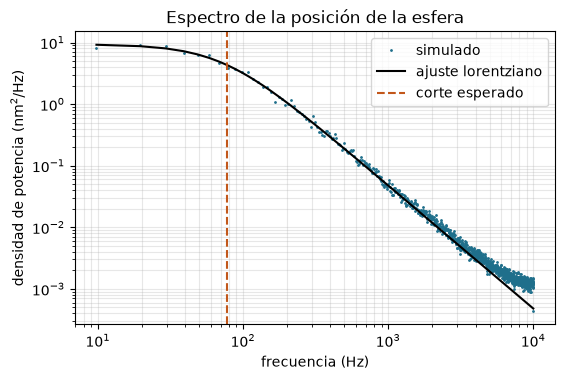

In [9]:
# el espectro en ejes logarítmicos con la lorentziana ajustada y la frecuencia de corte esperada
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.loglog(freq, power_density * 1e18, ".", markersize=2, color="#1f6f8b", label="simulado")
ax.loglog(freq, d_fit / (np.pi**2 * (freq**2 + fc_fit**2)) * 1e18, "k-", label="ajuste lorentziano")
ax.axvline(fc_expected, color="#c2571a", linestyle="--", label="corte esperado")
ax.set_xlabel("frecuencia (Hz)")
ax.set_ylabel("densidad de potencia (nm$^2$/Hz)")
ax.set_title("Espectro de la posición de la esfera")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

El espectro simulado tiene la forma lorentziana: una meseta a baja frecuencia, un codo, y una pendiente de $-2$ en dos décadas. La frecuencia de corte ajustada es 71,55 Hz frente a los 77,33 Hz esperados, una razón de 0,925, y la constante de difusión ajustada es 0,975 de $k_B T/\gamma$. Una rigidez leída del espectro sería entonces baja en cerca de 7 por ciento, lo que está dentro de la banda de 0,8 a 1,2 que fija la ficha del caso para esta razón y en línea con el sesgo que se sabe que tiene el ajuste linealizado con pocos segmentos. A alta frecuencia los puntos dejan la recta y se aplanan cerca de $10^{-3}$ nm$^2$/Hz, cerca de la frecuencia de Nyquist de 10 kHz: es el aliasing del integrador en tiempo discreto, y es la razón por la que el ajuste se detiene en cinco frecuencias de corte. La figura muestra una semilla, así que no puede decir cuánto de 7,5 por ciento es sesgo y cuánto es ruido; la prueba del motor del pipeline repite la corrida con tres semillas.

### Paso 4: la ley de Boltzmann

Una segunda verificación, independiente, no usa la dinámica en absoluto. En equilibrio la probabilidad de encontrar la esfera en $x$ es proporcional a $\exp[-U(x)/k_B T]$. La celda construye el potencial a lo largo de la fila del mapa que pasa por el pico, integra la densidad de Boltzmann en cada uno de 40 intervalos de posición, y mide la distancia de variación total entre eso y el histograma de las posiciones simuladas (0 si son idénticos, 1 si son disjuntos).

In [10]:
# el histograma de x frente a la ley de Boltzmann del potencial -profundidad I / I_max a lo largo de la fila
# por el pico
row = inten[iy_max, :] / inten.max()
check = boltzmann_check(x + start[0], lambda pos: -depth * np.interp(pos, xs, row), bead["temperature_k"])
print(f"variación total entre el histograma y la ley de Boltzmann: "
      f"{check['total_variation']:.4f}")

variación total entre el histograma y la ley de Boltzmann: 0.0462


Las barras son el histograma simulado y la línea negra es la predicción de Boltzmann.

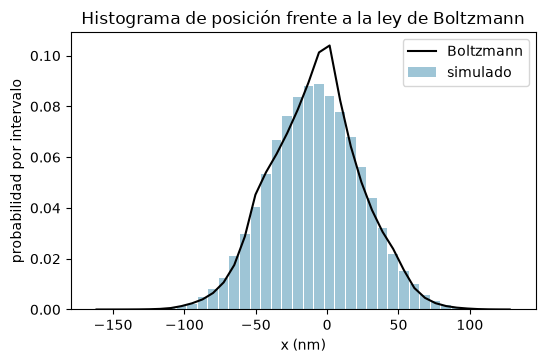

In [11]:
# probabilidad empírica y esperada de cada intervalo de posición
centres = (check["bin_centres_m"] - start[0]) * 1e9
fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.bar(centres, check["empirical"], width=np.diff(centres).mean() * 0.9, color="#9ec5d6", label="simulado")
ax.plot(centres, check["expected"], "k-", label="Boltzmann")
ax.set_xlabel("x (nm)")
ax.set_ylabel("probabilidad por intervalo")
ax.set_title("Histograma de posición frente a la ley de Boltzmann")
ax.legend()
plt.show()

El histograma sigue de cerca a la predicción: la distancia de variación total es 0,0462, de modo que las dos distribuciones difieren en 4,6 por ciento de su masa de probabilidad, y las barras quedan a ambos lados de la línea sin una desviación sistemática en las colas, donde un potencial anarmónico se haría notar. El residuo es coherente con el ruido de muestreo de una corrida que abarca unos 3000 tiempos de relajación. Esta verificación y el espectro son complementarios: el espectro prueba la escala de tiempo, que depende de la rigidez y del arrastre, y el histograma prueba el potencial, que depende de la rigidez y de la temperatura. Juntos dicen que la esfera simulada está en equilibrio en el potencial que se le dio. No dicen que ese potencial sea el correcto para una esfera real en una trampa real; eso depende de la física de la fuerza y del modelo del mapa.

## Resultados

**Respuesta:** Una esfera en la trampa calculada se comporta como dice la física del potencial, y su espectro de potencia devuelve la rigidez con una diferencia de cerca de 8 por ciento. El holograma del arreglo de 3 x 3 pone 0,0907 de la potencia de entrada en el pico de la trampa central, lo que con 10 mW da un potencial de 198,5 kBT de profundidad con una rigidez de 4,08 pN/um, una frecuencia de corte de 77,33 Hz y un tiempo de relajación de 2,058 ms. La esfera simulada tiene una posición rms de 32,7 nm frente al valor de equipartición de 31,6 nm, un espectro con la forma lorentziana cuya frecuencia de corte ajustada es 71,55 Hz (una razón de 0,925 respecto de la esperada), y un histograma de posición a una distancia de variación total de 0,0462 de la ley de Boltzmann.

Lo que el notebook no muestra es cómo varía la razón de 0,925 con la semilla, ni ninguna partícula distinta de una esfera en el régimen de Rayleigh; el valor absoluto de la rigidez lleva la salvedad del prefactor del vacío del pipeline.

## Resumen

- El mapa de intensidad de un holograma es un potencial, $U = -U_0 I/I_\text{máx}$, cuya profundidad, rigidez y frecuencia de corte salen de la polarizabilidad, la potencia del láser y la curvatura del punto.
- Una esfera sobreamortiguada se integra con un paso de a lo más $\tau/20$; su posición rms coincide con la equipartición con 3 por ciento.
- El ajuste lorentziano al espectro de posición devuelve la frecuencia de corte con una diferencia de 7,5 por ciento respecto de la usada, y la constante de difusión con 2,5 por ciento.
- El histograma de posición coincide con la ley de Boltzmann del potencial a una distancia de variación total de 0,0462.
- La verificación es interna: muestra que la simulación concuerda con su propio potencial, no que el potencial coincida con un instrumento.

## Referencias

- Tolic-Norrelykke et al. (2006). Calibration of optical tweezers with positional detection in the back focal plane. Review of Scientific Instruments 77, 103101. https://arxiv.org/abs/physics/0603037
- Grimm, Weidemuller and Ovchinnikov (2000). Optical dipole traps for neutral atoms. https://arxiv.org/abs/physics/9902072